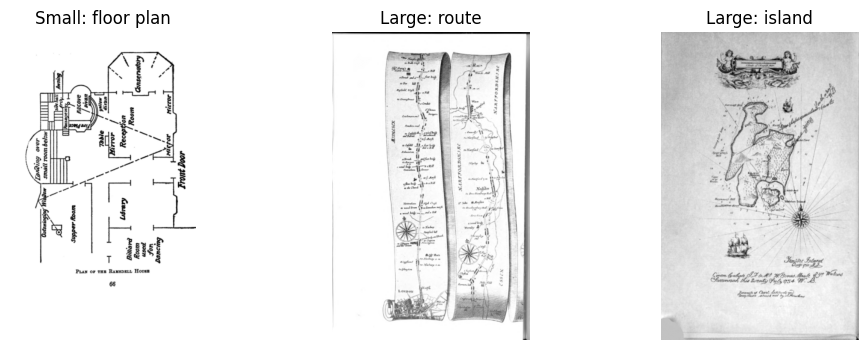

In [1]:
#POC Features
#feature 1: wall detection
#feature 2: room detection
#feature 3: corner detection

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage.color import rgb2gray
from skimage.exposure import rescale_intensity
from skimage.feature import canny, corner_harris, corner_peaks, hog, local_binary_pattern
from skimage.transform import probabilistic_hough_line, resize

ROOT = Path("..") if (Path.cwd() / "feature_checkpoint.ipynb").exists() else Path(".")
samples = {
    "Small: floor plan": ROOT / "data/samples/woman_in_the_alcove.jpg",
    "Large: route": ROOT / "data/samples/colonel_jacques.jpg",
    "Large: island": ROOT / "data/samples/treasure_island.jpg",
}

def load_gray(path, max_side=512):
    gray = rgb2gray(np.asarray(Image.open(path).convert("RGB"), dtype=np.float32) / 255.0)
    h, w = gray.shape
    s = max_side / max(h, w)
    if s < 1:
        gray = resize(gray, (int(h * s), int(w * s)), anti_aliasing=True)
    return gray

images = {name: load_gray(path) for name, path in samples.items()}

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, gray) in zip(axes, images.items()):
    ax.imshow(gray, cmap="gray")
    ax.set_title(name)
    ax.axis("off")
plt.show()


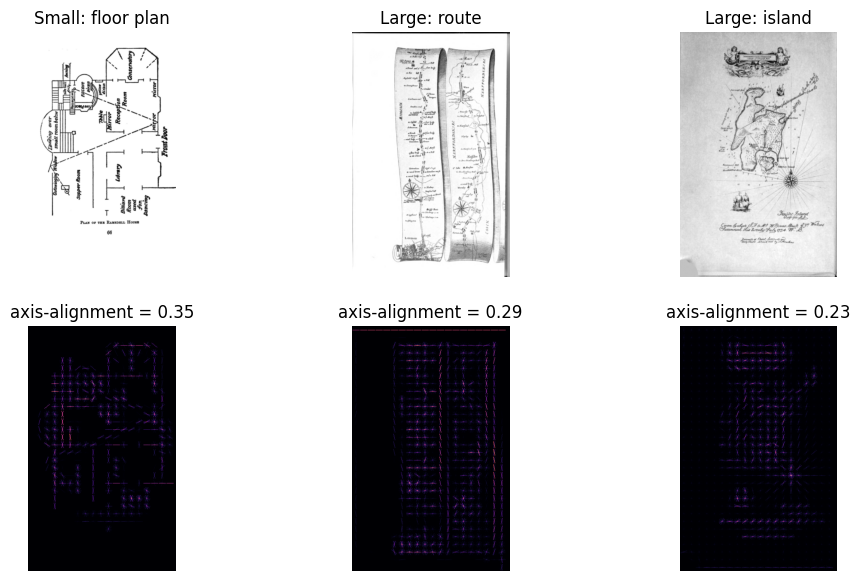

{'Small: floor plan': 0.349, 'Large: route': 0.295, 'Large: island': 0.229}


In [2]:
# Feature 1 HOG. Walls are either 0 or 90 deg, unlike coastlines
hog_out = {}
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for i, (name, gray) in enumerate(images.items()):
    feats, hog_img = hog(
        gray, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(1, 1),
        visualize=True, feature_vector=False, channel_axis=None,
    )
    hist = feats.reshape(-1, 9).mean(axis=0)
    hist = hist / hist.sum()
    hog_out[name] = {"hist": hist, "axis": float(hist[0] + hist[4])}
    axes[0, i].imshow(gray, cmap="gray")
    axes[0, i].set_title(name)
    axes[1, i].imshow(rescale_intensity(hog_img), cmap="magma")
    axes[1, i].set_title(f"axis-alignment = {hog_out[name]['axis']:.2f}")
    axes[0, i].axis("off")
    axes[1, i].axis("off")
plt.show()
print({k: round(v["axis"], 3) for k, v in hog_out.items()})


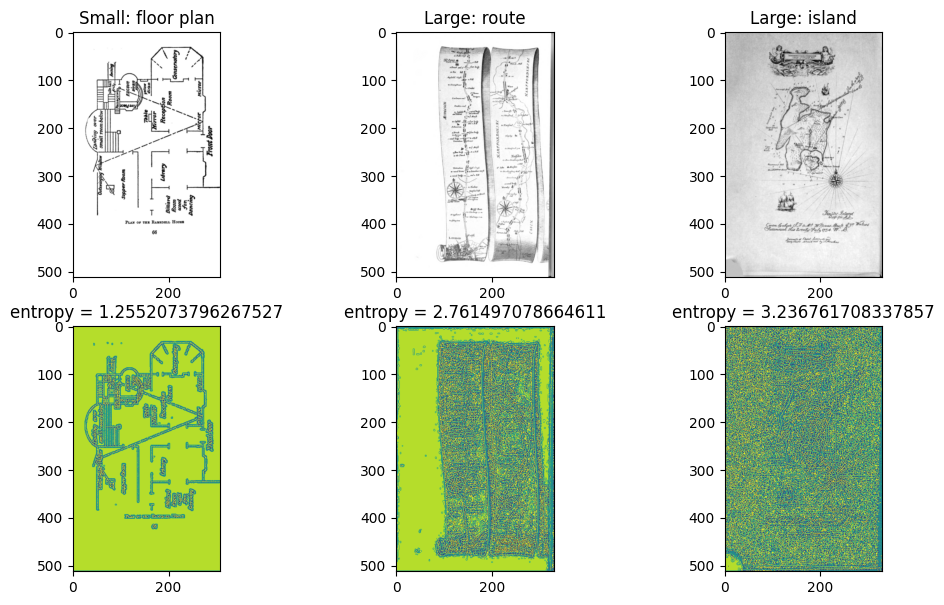

In [3]:
# Feature 2 LBP texture. Empty rooms have low entropy; hatching/stipple have high.
lbp_out = {}
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for i, (name, gray) in enumerate(images.items()):
    lbp = local_binary_pattern((gray * 255).astype(np.uint8), P=8, R=1, method="uniform")
    hist, _ = np.histogram(lbp.ravel(), bins=10, range=(0, 10), density=True)
    entropy = float(-np.sum(hist * np.log2(hist + 1e-12)))
    lbp_out[name] = entropy
    axes[0, i].imshow(gray, cmap="gray")
    axes[0, i].set_title(name)
    axes[1, i].imshow(lbp, cmap="viridis")
    axes[1, i].set_title(f"entropy = {entropy}")
plt.show()


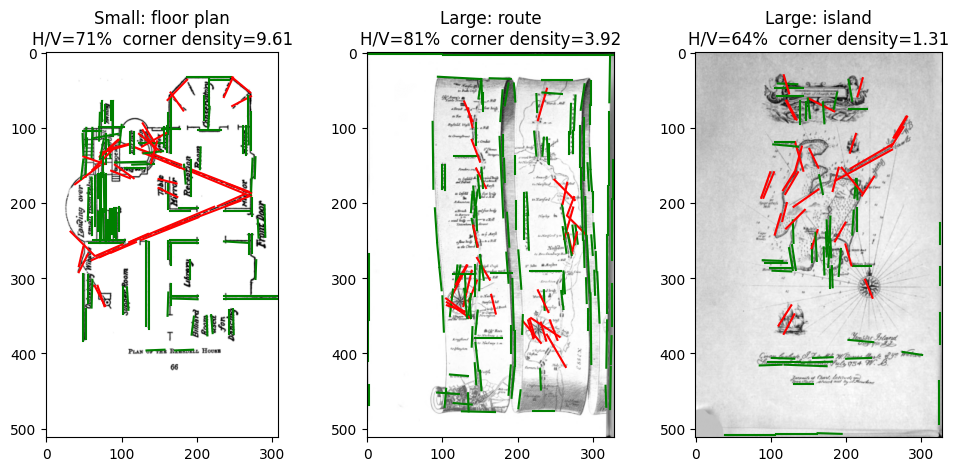

In [4]:
# Feature 3: Horizontal/Vertical fraction + corner density.
#using hough lines and Harris corners
def angle(p0, p1):
    return np.degrees(np.arctan2(p1[1] - p0[1], p1[0] - p0[0])) % 180

def is_hv(a, tol=12):
    return min(a, abs(a - 90), abs(a - 180)) <= tol

fig, axes = plt.subplots(1, 3, figsize=(12, 5))
for ax, (name, gray) in zip(axes, images.items()):
    edges = canny(gray, sigma=1.8)
    np.random.seed(0)
    lines = probabilistic_hough_line(edges, threshold=12, line_length=max(24, int(0.06 * min(gray.shape))), line_gap=4)
    hv = np.mean([is_hv(angle(p0, p1)) for p0, p1 in lines]) if lines else 0.0
    corners = corner_peaks(corner_harris(gray), min_distance=8, threshold_rel=0.08)
    dens = len(corners) / gray.size * 1e4
    ax.imshow(gray, cmap="gray")
    for p0, p1 in lines:
        ax.plot([p0[0], p1[0]], [p0[1], p1[1]], color="green" if is_hv(angle(p0, p1)) else "red")
    ax.set_title(f"{name}\nH/V={hv:.0%}  corner density={dens:.2f}")
plt.show()
